# Run previous notebook

In [110]:
# %run 01_eda_freight.ipynb

In [111]:
# from IPython.utils.capture import capture_output

# with capture_output():
#     get_ipython().run_line_magic('run', '01_eda_freight.ipynb')

In [112]:
# %pip install phik

In [113]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
# import phik
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, max_error
from sklearn.base import clone
# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

In [114]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True) 
# Drop empty rows
df_freight = df_freight.dropna(how="all")

# Weather Data
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True) # dates are dd/mm/yyyy
# Drop empty rows
df_weather = df_weather.dropna(how="all")
df_weather.rename(columns={'date': 'Date'}, inplace=True)

In [115]:
df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')

In [116]:
df_freight.shape, df_weather.shape, df_complete.shape

((1469, 8), (3652, 25), (1469, 32))

In [117]:
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avg_uv_index,avgtemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,1.0,2.0,...,0.0,1.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,1.0,4.0,...,0.0,1.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,1.0,...,0.0,1.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,1.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,1.0,-1.0,...,0.0,1.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [118]:
df_complete.shape

(1469, 32)

In [119]:
df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)

In [120]:
df_complete.dropna(subset=['Freight'], inplace=True)
# Price 5 rows ahead (the last 5 rows get NaN because they have no future)
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)
# Drop those last 5 rows
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)


# 2. Features

- Que features são mais importantes para o modelo?
- Que features são redundantes?
- Que tipo de split fazer? Cross-validation? Ter a certeza que nao existe data leakage
- Que modelos usar?
- Experimentar PCA para reduzir Weather features e gas price features?

Eliminar features claramente redundantes

In [121]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[us]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1436 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity              1449 no

In [122]:
# corr_above30 = (
#     correlation_matrix['Freight_5days']
#     .loc[lambda s: s > 0.30]            # arbitrary value could be 0.4, 0.5 etc
#     .drop('Freight_5days', errors='ignore')   # remove the target's correlation with itself (1.0)
#     .sort_values(ascending=False)
#     .rename('Correlation')
#     .to_frame()
# )

# corr_above30.round(3)

Encoding features

In [123]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[us]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1436 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity              1449 no

Encoding Date into cos e sin

In [124]:
day = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * day / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * day / 365.25)

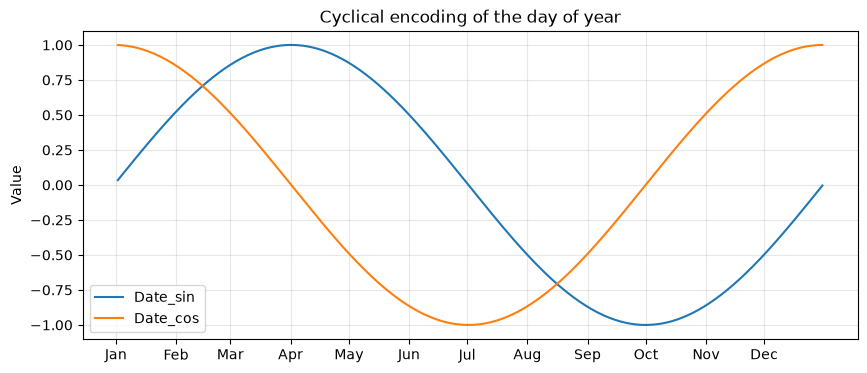

In [125]:
d = df_complete.assign(day=day).sort_values("day")
month_starts = pd.date_range("2021-01-01", periods=12, freq="MS")   # 1st of each month

plt.figure(figsize=(10, 4))
plt.plot(d["day"], d["Date_sin"], label="Date_sin")
plt.plot(d["day"], d["Date_cos"], label="Date_cos")
plt.xticks(month_starts.dayofyear, month_starts.strftime("%b"))
plt.ylabel("Value")
plt.title("Cyclical encoding of the day of year")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [126]:
df_complete[["Date_sin", "Date_cos"]].head()

,Date_sin,Date_cos
0,0.051584,0.998669
1,0.068755,0.997634
2,0.120126,0.992759
3,0.137185,0.990545
4,0.154204,0.988039


Encoding Weather Description

In [127]:
df_complete["weather_descriptions"] = df_complete["weather_descriptions"].str.strip("[]'")

### **VERIFICAR QUANDO FAZEMOS ENCONDING SE UMA DAS COLUNAS É REMOVIDA, PARA EVITAR REDUNDÂNCIA**

In [128]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions'], prefix='weather', dtype=int)

In [129]:
df_complete = pd.get_dummies(df_complete, columns=['moon_phase'], prefix='moon', dtype=int)

In [130]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow',
       'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust',
       'Freight_5days', 'Date_sin', 'Date_cos', 'weather_Clear',
       'weather_Cloudy', 'weather_Fog', 'weather_Freezing fog',
       'weather_Light rain', 'weather_Light rain shower', 'weather_Mist',
       'weather_Moderate or heavy rain shower', 'weather_Moderate rain',
       'weather_Overcast', 'weather_Partly cloudy',
       'weather_Patchy light rain with thunder',
       'weather_Patchy rain possible', 'weather_Thundery outbreaks possible',
       'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter',
       'moon_New Moon', 'moon_Waning Crescent', 'moon_Waning Gibbous',
       'moon_Waxing Crescent', 'm

In [131]:
df_complete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 51 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    1449 non-null   datetime64[us]
 1   Freight                                 1449 non-null   float64       
 2   Mogas_Flat                              1449 non-null   float64       
 3   Brent_flat                              1449 non-null   float64       
 4   Diesel_Flat                             1449 non-null   float64       
 5   Heating_Flat                            1449 non-null   float64       
 6   Kaub_level                              1436 non-null   float64       
 7   freight_ar                              714 non-null    float64       
 8   avgtemp                                 1449 non-null   float64       
 9   cloudcover                              1449 non-null   float64

## Missing values

Strategies:
-   **freight_ar**
    -   drop column
    -   replace missing values with mean (not the best approach probably)
-   **Kaub level**
    - replace with the mean between the values right before and after

In [132]:
# Kaub_level: average of the value before and the value after each gap
df_complete["Kaub_level"] = df_complete["Kaub_level"].interpolate(method="linear", limit_area="inside")

# freight_ar: fill missing values with the column mean
df_complete["freight_ar"] = df_complete["freight_ar"].fillna(df_complete["freight_ar"].mean())
#drop freight_ar from the dataset
#df = df_complete.drop(columns=["freight_ar"])

# 1. Baseline Model

In [133]:
col = 'Freight'

# Garante a ordem temporal (se tiveres uma coluna Date)
df_sorted = df_complete.sort_values('Date').reset_index(drop=True)
y = df_sorted[col]

# 1) Maior amplitude em 5 linhas seguidas (como antes)
amplitude = y.rolling(5).max() - y.rolling(5).min()
print('Maior amplitude em 5 linhas:', amplitude.max())

# 2) Previsão = média dos 5 dias anteriores (shift(1) exclui o próprio dia)
pred_mean5 = y.shift(1).rolling(5).mean()
erro_mean5 = (y - pred_mean5).abs()

# 3) Previsão = valor do dia anterior
pred_naive = y.shift(1)
erro_naive = (y - pred_naive).abs()

# Resultados
for nome, erro, pred in [('Média dos 5 dias anteriores', erro_mean5, pred_mean5),
                         ('Valor do dia anterior', erro_naive, pred_naive)]:
    i = erro.idxmax()
    print(f'\n{nome}')
    print('  Erro máximo:', round(erro[i], 2))
    print('  Erro médio (MAE):', round(erro.mean(), 2))
    print('  Valor real:', y[i], '| Previsão:', round(pred[i], 2))
    print('  Linha:', i)

Maior amplitude em 5 linhas: 224.39999999999998

Média dos 5 dias anteriores
  Erro máximo: 177.39
  Erro médio (MAE): 3.89
  Valor real: 151.35 | Previsão: 328.74
  Linha: 1438

Valor do dia anterior
  Erro máximo: 112.35
  Erro médio (MAE): 1.41
  Valor real: 248.1 | Previsão: 360.45
  Linha: 1437


In [134]:
# Previsões (usam só informação até ao dia t)
df_complete['pred_hoje']     = df_complete['Freight']
df_complete['pred_media5']   = df_complete['Freight'].rolling(5).mean()
# Hoje + variação dos últimos 5 dias = 2*y(t) - y(t-5)
df_complete['pred_momentum'] = df_complete['Freight'] + df_complete['Freight'].diff(5)

previsores = {
    'Preço de hoje': 'pred_hoje',
    'Média dos últimos 5 dias': 'pred_media5',
    'Hoje + variação 5 dias': 'pred_momentum',
}

# Mesmas linhas para os três métodos (media5 e momentum geram NaN nas primeiras linhas)
av = df_complete.dropna(subset=list(previsores.values()) + ['Freight_5days'])

def metricas(y_true, y_pred):
    erro = y_true - y_pred
    return {
        'MAE': erro.abs().mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'Erro máx': erro.abs().max(),
    }

# Todos os dias
resultados = pd.DataFrame({
    nome: metricas(av['Freight_5days'], av[col])
    for nome, col in previsores.items()
}).T

print(f'Nº de previsões avaliadas: {len(av)}')
display(resultados.round(2))

# Só dias extremos (top 10% do preço real a 5 dias)
extremo = av['Freight_5days'] >= av['Freight_5days'].quantile(0.90)

resultados_ext = pd.DataFrame({
    nome: metricas(av.loc[extremo, 'Freight_5days'], av.loc[extremo, col])
    for nome, col in previsores.items()
}).T

print('Dias extremos:')
display(resultados_ext.round(2))

Nº de previsões avaliadas: 1444


,MAE,RMSE,Erro máx
Preço de hoje,6.39,15.97,227.7
Média dos últimos 5 dias,8.47,19.44,214.2
Hoje + variação 5 dias,7.46,19.24,247.8


Dias extremos:


,MAE,RMSE,Erro máx
Preço de hoje,22.79,41.97,227.7
Média dos últimos 5 dias,26.96,44.07,214.2
Hoje + variação 5 dias,22.59,42.79,247.8


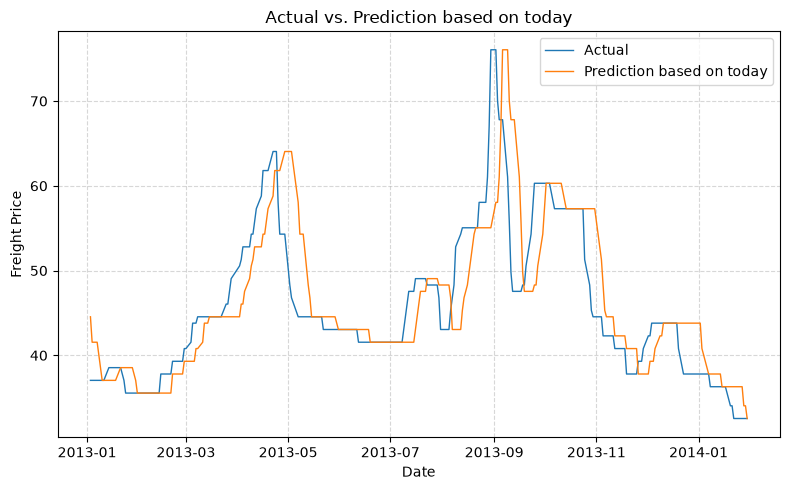

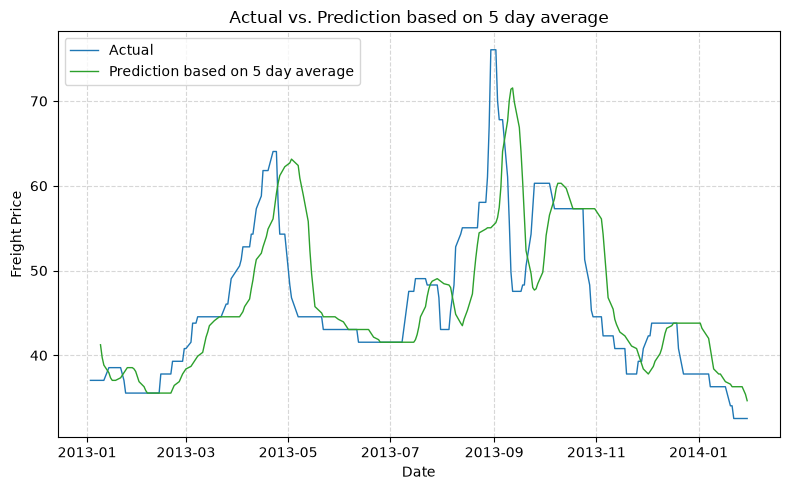

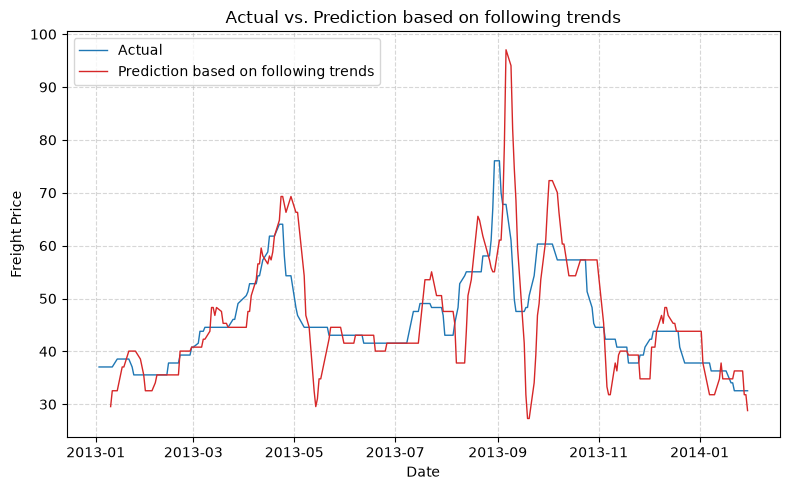

In [135]:
year = int(365 * 5 / 7)
subset = df_complete.iloc[:year]
x = subset['Date']

# Define (column_name, legend_label, line_color) for each baseline
baselines = [
    ('pred_hoje', 'Prediction based on today', '#ff7f0e'),
    ('pred_media5', 'Prediction based on 5 day average', '#2ca02c'),
    ('pred_momentum', 'Prediction based on following trends', '#d62728'),
]

for col, label, color in baselines:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    ax.plot(x, subset['Freight_5days'], label='Actual', color='#1f77b4', linewidth=1)
    ax.plot(x, subset[col], label=label, color=color, linewidth=1)
    
    ax.set(title=f'Actual vs. {label}', xlabel='Date', ylabel='Freight Price')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    
    plt.tight_layout()

plt.show()

Cada hipotese de baseline tem vantagens e desvantagens. Pelos resultados a melhor baseline é assumir o preço de hoje para a previsao.
A media dos ultimos 5 dias tende  atrasar o sinal da trend na previsao piorando os resultados. 
A tentativa de seguir a tendencia (Hoje + variação) resulta em menores erros no inicio de tendencias mas erros amplificados quando o crescimento/diminuição de preço muda de sentido.

Por enquanto a baseline escolhida é o preço do proprio dia

## Train/Test split

TimeSeriesSplit
-   no max  max_train_size
-   max_train_size=500

In [136]:
df_model = df_complete.copy()  # Create a copy of df_complete to avoid modifying the original DataFrame

target = "Freight_5days"
baselines = ["pred_hoje", "pred_media5", "pred_momentum"]  
cols = ["Date"] # keep for comparison, not as features
drop_cols = cols + [target] + baselines

X = df_model.drop(columns=drop_cols, errors="ignore")
y = df_model[target]
dates = df_model["Date"]

# gap=5: the last 5 training rows have targets that fall inside the test period -> leave them out
splitters = {
    "expanding (default)": TimeSeriesSplit(n_splits=5, gap=5),                        # train on all past data
    "rolling (500)":       TimeSeriesSplit(n_splits=5, gap=5, max_train_size=500),    # train on the last 500 rows only
}

folds = []
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        folds.append({
            "scheme": scheme,
            "fold": fold,
            "train_start": dates.iloc[train_idx[0]].date(), "train_end": dates.iloc[train_idx[-1]].date(),
            "train_rows": len(train_idx),
            "test_start": dates.iloc[test_idx[0]].date(), "test_end": dates.iloc[test_idx[-1]].date(),
            "test_rows": len(test_idx),
        })
folds = pd.DataFrame(folds).set_index(["scheme", "fold"])
folds

train_start   train_end  train_rows  test_start  \
scheme              fold                                                   
expanding (default) 0     2013-01-03  2013-12-23         239  2014-01-08   
                    1     2013-01-03  2014-12-22         480  2015-01-07   
                    2     2013-01-03  2015-12-18         721  2016-01-04   
                    3     2013-01-03  2016-12-16         962  2016-12-28   
                    4     2013-01-03  2017-12-15        1203  2017-12-27   
rolling (500)       0     2013-01-03  2013-12-23         239  2014-01-08   
                    1     2013-01-03  2014-12-22         480  2015-01-07   
                    2     2013-11-28  2015-12-18         500  2016-01-04   
                    3     2014-11-27  2016-12-16         500  2016-12-28   
                    4     2015-11-25  2017-12-15         500  2017-12-27   

                            test_end  test_rows  
scheme              fold                         
expanding (default) 0     2015-01-05        241  
                    1     2015-12-30        241  
                    2     2016-12-23        241  
                    3     2017-12-22        241  
                    4     2018-12-18        241  
rolling (500)       0     2015-01-05        241  
                    1     2015-12-30        241  
                    2     2016-12-23        241  
                    3     2017-12-22        241  
                    4     2018-12-18        241

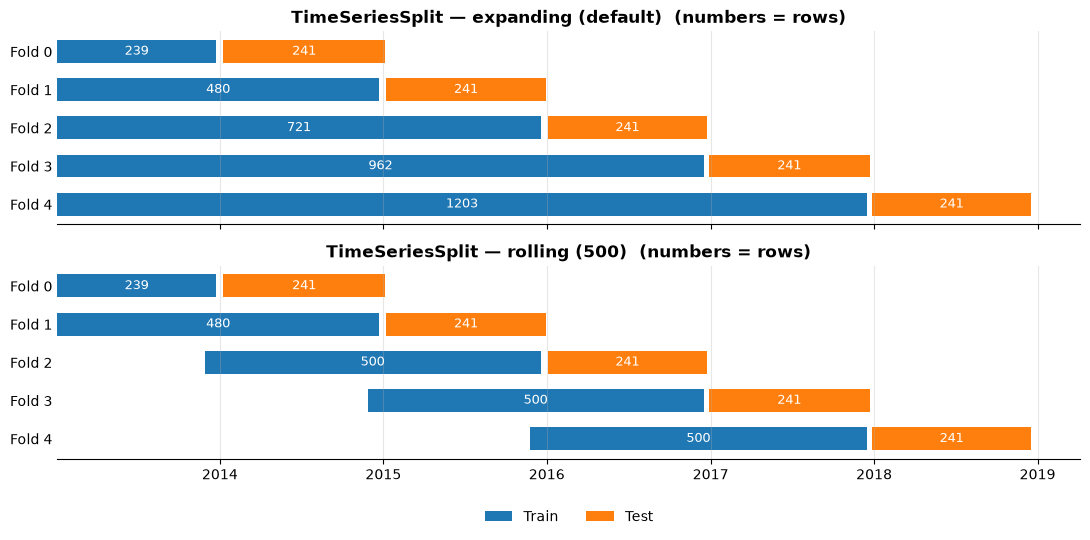

In [137]:
fig, axes = plt.subplots(len(splitters), 1, figsize=(11, 5.5), sharex=True)
for ax, (scheme, tscv) in zip(axes, splitters.items()):
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        tr0, tr1 = dates.iloc[train_idx[0]], dates.iloc[train_idx[-1]]
        te0, te1 = dates.iloc[test_idx[0]], dates.iloc[test_idx[-1]]
        ax.barh(fold, tr1 - tr0, left=tr0, height=0.6, color="tab:blue", label="Train" if fold == 0 else None)
        ax.barh(fold, te1 - te0, left=te0, height=0.6, color="tab:orange", label="Test" if fold == 0 else None)
        ax.text(tr0 + (tr1 - tr0) / 2, fold, f"{len(train_idx)}", va="center", ha="center", color="white", fontsize=9)
        ax.text(te0 + (te1 - te0) / 2, fold, f"{len(test_idx)}", va="center", ha="center", color="white", fontsize=9)
    ax.set_yticks(range(tscv.n_splits), [f"Fold {i}" for i in range(tscv.n_splits)])
    ax.invert_yaxis()
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"TimeSeriesSplit — {scheme}  (numbers = rows)", loc="center", fontweight="bold")
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

## Modeling

Strategies:
-   1. Using all features
-   2. keeping only energies, kaub level, 

### Linear Regression Ridge

In [138]:
models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    #"RandomForest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
    # "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
preds = []   # store every prediction for plotting
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        "MAE": mean_absolute_error(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            "MAE": mean_absolute_error(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name, "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)
res.pivot(index=["scheme", "fold"], columns="model", values="MAE").round(2)

model                     Benchmark (today)  Ridge
scheme              fold                          
expanding (default) 0                  2.27   9.21
                    1                  8.02  14.49
                    2                  5.43   9.62
                    3                  6.50   8.13
                    4                 12.65  16.25
rolling (500)       0                  2.27   9.21
                    1                  8.02  14.49
                    2                  5.43  11.51
                    3                  6.50  11.69
                    4                 12.65  23.77

In [139]:
spike_threshold = y.quantile(0.9)   # top 10% of freight values = "spike" days

def metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    spike = y_true > spike_threshold
    return {
        "MAE":       mean_absolute_error(y_true, y_pred),                     # typical error
        "RMSE":      np.sqrt(mean_squared_error(y_true, y_pred)),             # punishes big misses
        "MAPE_%":    np.mean(np.abs((y_true - y_pred) / y_true)) * 100,       # error as % of the price
        "MaxErr":    max_error(y_true, y_pred),                               # single worst prediction
        "R2":        r2_score(y_true, y_pred),                                # share of variation explained
        "MAE_spike": mean_absolute_error(y_true[spike], y_pred[spike]) if spike.any() else np.nan,   # error on spike days only
    }

def plot_predictions(preds, model, scheme="expanding (default)"):
    p = preds[(preds["scheme"] == scheme) & (preds["model"] == model)]
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(p["Date"], p["actual"], color="black", lw=1.1, label="Actual (5 days ahead)")
    ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.4, alpha=0.85, label=f"{model} prediction")
    ax.plot(p["Date"], p["benchmark"], color="tab:red", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")
    for f, g in p.groupby("fold"):
        ax.axvline(g["Date"].min(), color="grey", lw=0.6, ls=":")   # start of each test fold
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
    ax.set_title(f"Out-of-sample predictions ({model}) — {scheme} (dotted lines = fold starts)", loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [140]:
models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    #"RandomForest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
    # "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
preds = []   # store every prediction for plotting
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        **metrics(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            **metrics(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name, "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)

In [141]:
metric_cols = ["MAE", "RMSE", "MAPE_%", "MaxErr", "R2", "MAE_spike"]
res.pivot_table(index=["scheme", "fold"], columns="model", values=metric_cols).round(2)

MAE                MAE_spike         \
model                    Benchmark (today)  Ridge Benchmark (today)  Ridge   
scheme              fold                                                     
expanding (default) 0                 2.27   9.21               NaN    NaN   
                    1                 8.02  14.49             20.56  39.50   
                    2                 5.43   9.62             20.63  24.07   
                    3                 6.50   8.13              8.21  11.43   
                    4                12.65  16.25             27.22  36.76   
rolling (500)       0                 2.27   9.21               NaN    NaN   
                    1                 8.02  14.49             20.56  39.50   
                    2                 5.43  11.51             20.63  25.31   
                    3                 6.50  11.69              8.21  14.24   
                    4                12.65  23.77             27.22  51.43   

                                    MAPE_%                   MaxErr          \
model                    Benchmark (today)  Ridge Benchmark (today)   Ridge   
scheme              fold                                                      
expanding (default) 0                 5.36  22.13             11.25   24.25   
                    1                 8.06  14.97             87.00   72.04   
                    2                 7.73  18.88             33.00   31.97   
                    3                10.51  14.02             75.00   66.92   
                    4                 9.47  11.95            227.70  196.42   
rolling (500)       0                 5.36  22.13             11.25   24.25   
                    1                 8.06  14.97             87.00   72.04   
                    2                 7.73  23.74             33.00   33.14   
                    3                10.51  21.35             75.00   67.43   
                    4                 9.47  18.65            227.70  171.16   

                                        R2                    RMSE         
model                    Benchmark (today) Ridge Benchmark (today)  Ridge  
scheme              fold                                                   
expanding (default) 0                 0.69 -2.79              3.28  11.49  
                    1                 0.90  0.82             15.83  20.93  
                    2                 0.85  0.78              9.55  11.48  
                    3                 0.81  0.80             11.96  12.19  
                    4                 0.90  0.90             31.67  31.48  
rolling (500)       0                 0.69 -2.79              3.28  11.49  
                    1                 0.90  0.82             15.83  20.93  
                    2                 0.85  0.70              9.55  13.36  
                    3                 0.81  0.70             11.96  15.13  
                    4                 0.90  0.87             31.67  36.67

In [142]:
res.groupby(["scheme", "model"])[metric_cols].mean().round(2)

MAE   RMSE  MAPE_%  MaxErr    R2  \
scheme              model                                                   
expanding (default) Benchmark (today)   6.97  14.46    8.23   86.79  0.83   
                    Ridge              11.54  17.51   16.39   78.32  0.10   
rolling (500)       Benchmark (today)   6.97  14.46    8.23   86.79  0.83   
                    Ridge              14.14  19.51   20.17   73.60  0.06   

                                       MAE_spike  
scheme              model                         
expanding (default) Benchmark (today)      19.15  
                    Ridge                  27.94  
rolling (500)       Benchmark (today)      19.15  
                    Ridge                  32.62

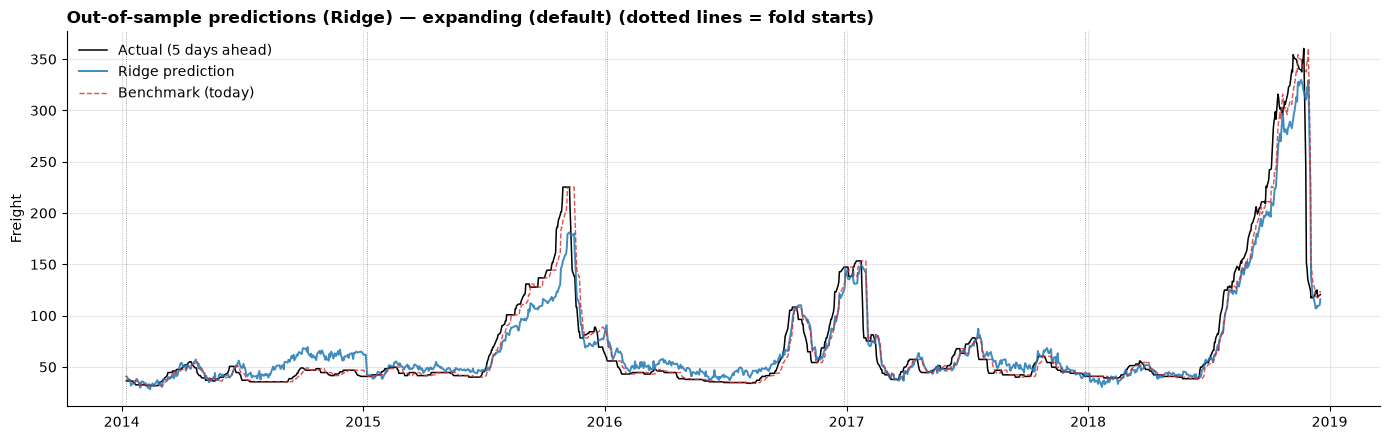

In [143]:
plot_predictions(preds, model="Ridge", scheme="expanding (default)")

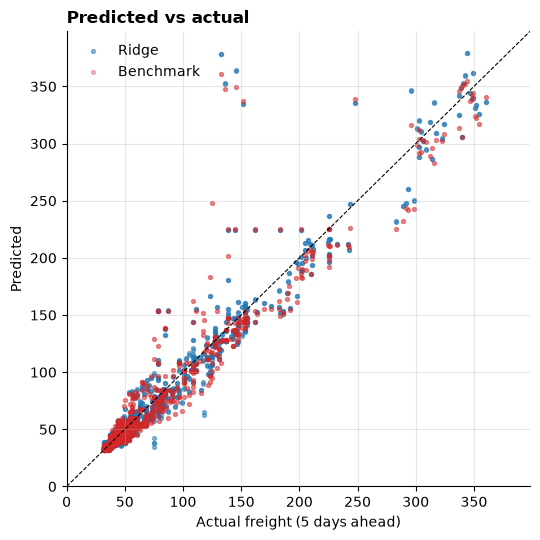

In [144]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(p["actual"], p["pred"], s=8, alpha=0.5, color="tab:blue", label="Ridge")
ax.scatter(p["actual"], p["benchmark"], s=8, alpha=0.3, color="tab:red", label="Benchmark")
lim = [0, max(p["actual"].max(), p["pred"].max()) * 1.05]
ax.plot(lim, lim, color="black", lw=0.8, ls="--")   # perfect prediction line
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual freight (5 days ahead)"); ax.set_ylabel("Predicted")
ax.set_title("Predicted vs actual", loc="left", fontweight="bold")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [145]:

models = {
    #"Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "RandomForest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
    # "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
preds = []   # store every prediction for plotting
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        **metrics(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            **metrics(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name, "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)

In [146]:
metric_cols = ["MAE", "RMSE", "MAPE_%", "MaxErr", "R2", "MAE_spike"]
res.pivot_table(index=["scheme", "fold"], columns="model", values=metric_cols).round(2)

MAE                      MAE_spike  \
model                    Benchmark (today) RandomForest Benchmark (today)   
scheme              fold                                                    
expanding (default) 0                 2.27         5.00               NaN   
                    1                 8.02        34.85             20.56   
                    2                 5.43         8.67             20.63   
                    3                 6.50         9.61              8.21   
                    4                12.65        23.99             27.22   
rolling (500)       0                 2.27         5.00               NaN   
                    1                 8.02        34.85             20.56   
                    2                 5.43         9.08             20.63   
                    3                 6.50        10.60              8.21   
                    4                12.65        53.58             27.22   

                                                 MAPE_%               \
model                    RandomForest Benchmark (today) RandomForest   
scheme              fold                                               
expanding (default) 0             NaN              5.36        12.90   
                    1          113.88              8.06        27.70   
                    2           48.03              7.73        12.32   
                    3           28.97             10.51        14.30   
                    4           61.75              9.47        12.32   
rolling (500)       0             NaN              5.36        12.90   
                    1          113.88              8.06        27.70   
                    2           48.37              7.73        12.83   
                    3           28.51             10.51        16.44   
                    4          144.28              9.47        25.57   

                                    MaxErr                             R2  \
model                    Benchmark (today) RandomForest Benchmark (today)   
scheme              fold                                                    
expanding (default) 0                11.25        12.35              0.69   
                    1                87.00       173.14              0.90   
                    2                33.00        55.98              0.85   
                    3                75.00       107.48              0.81   
                    4               227.70       177.30              0.90   
rolling (500)       0                11.25        12.35              0.69   
                    1                87.00       173.14              0.90   
                    2                33.00        58.48              0.85   
                    3                75.00       107.03              0.81   
                    4               227.70       273.75              0.90   

                                                   RMSE               
model                    RandomForest Benchmark (today) RandomForest  
scheme              fold                                              
expanding (default) 0            0.06              3.28         5.73  
                    1           -0.32             15.83        56.87  
                    2            0.57              9.55        16.05  
                    3            0.59             11.96        17.53  
                    4            0.76             31.67        48.92  
rolling (500)       0            0.06              3.28         5.73  
                    1           -0.32             15.83        56.87  
                    2            0.53              9.55        16.72  
                    3            0.56             11.96        18.24  
                    4            0.09             31.67        95.54

In [147]:
res.groupby(["scheme", "model"])[metric_cols].mean().round(2)

MAE   RMSE  MAPE_%  MaxErr    R2  \
scheme              model                                                   
expanding (default) Benchmark (today)   6.97  14.46    8.23   86.79  0.83   
                    RandomForest       16.42  29.02   15.91  105.25  0.33   
rolling (500)       Benchmark (today)   6.97  14.46    8.23   86.79  0.83   
                    RandomForest       22.62  38.62   19.09  124.95  0.18   

                                       MAE_spike  
scheme              model                         
expanding (default) Benchmark (today)      19.15  
                    RandomForest           63.16  
rolling (500)       Benchmark (today)      19.15  
                    RandomForest           83.76

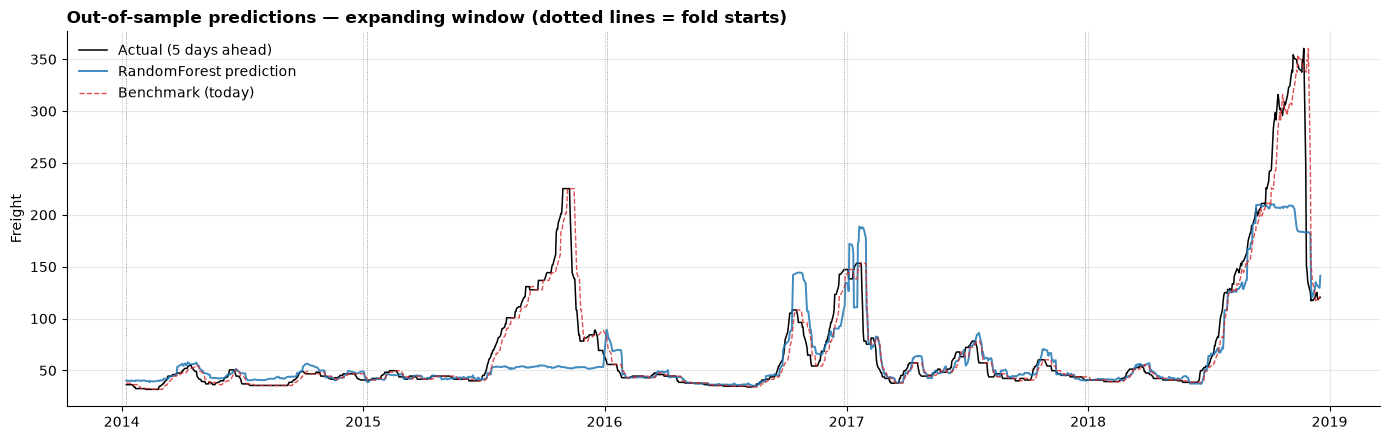

In [148]:
p = preds[(preds["scheme"] == "expanding (default)") & (preds["model"] == "RandomForest")]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["Date"], p["actual"], color="black", lw=1.1, label="Actual (5 days ahead)")
ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.4, alpha=0.85, label="RandomForest prediction")
ax.plot(p["Date"], p["benchmark"], color="tab:red", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")
for f, g in p.groupby("fold"):
    ax.axvline(g["Date"].min(), color="grey", lw=0.6, ls=":")   # start of each test fold
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Out-of-sample predictions — expanding window (dotted lines = fold starts)", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

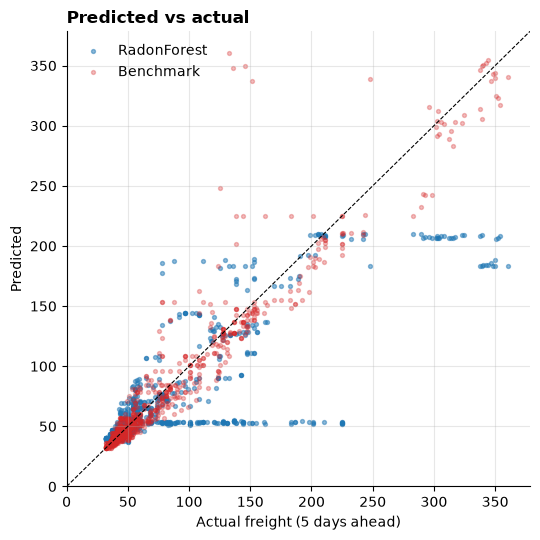

In [149]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(p["actual"], p["pred"], s=8, alpha=0.5, color="tab:blue", label="RadonForest")
ax.scatter(p["actual"], p["benchmark"], s=8, alpha=0.3, color="tab:red", label="Benchmark")
lim = [0, max(p["actual"].max(), p["pred"].max()) * 1.05]
ax.plot(lim, lim, color="black", lw=0.8, ls="--")   # perfect prediction line
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual freight (5 days ahead)"); ax.set_ylabel("Predicted")
ax.set_title("Predicted vs actual", loc="left", fontweight="bold")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [150]:

models = {
    #"Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    #"RandomForest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
    "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
preds = []   # store every prediction for plotting
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        **metrics(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            **metrics(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name, "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)

In [151]:
metric_cols = ["MAE", "RMSE", "MAPE_%", "MaxErr", "R2", "MAE_spike"]
res.pivot_table(index=["scheme", "fold"], columns="model", values=metric_cols).round(2)

MAE                MAE_spike          \
model                    Benchmark (today) HistGB Benchmark (today)  HistGB   
scheme              fold                                                      
expanding (default) 0                 2.27   6.53               NaN     NaN   
                    1                 8.02  35.75             20.56  114.39   
                    2                 5.43  10.47             20.63   39.12   
                    3                 6.50  11.00              8.21   34.38   
                    4                12.65  27.01             27.22   70.85   
rolling (500)       0                 2.27   6.53               NaN     NaN   
                    1                 8.02  35.75             20.56  114.39   
                    2                 5.43  10.90             20.63   38.31   
                    3                 6.50  12.33              8.21   31.25   
                    4                12.65  56.45             27.22  154.19   

                                    MAPE_%                   MaxErr          \
model                    Benchmark (today) HistGB Benchmark (today)  HistGB   
scheme              fold                                                      
expanding (default) 0                 5.36  16.75             11.25   15.35   
                    1                 8.06  28.91             87.00  174.07   
                    2                 7.73  15.53             33.00   82.50   
                    3                10.51  16.01             75.00  127.92   
                    4                 9.47  13.41            227.70  214.50   
rolling (500)       0                 5.36  16.75             11.25   15.35   
                    1                 8.06  28.91             87.00  174.07   
                    2                 7.73  16.38             33.00   86.29   
                    3                10.51  19.01             75.00  117.87   
                    4                 9.47  26.21            227.70  276.16   

                                        R2                     RMSE         
model                    Benchmark (today) HistGB Benchmark (today) HistGB  
scheme              fold                                                    
expanding (default) 0                 0.69  -0.58              3.28   7.41  
                    1                 0.90  -0.36             15.83  57.57  
                    2                 0.85   0.28              9.55  20.73  
                    3                 0.81   0.41             11.96  21.10  
                    4                 0.90   0.68             31.67  56.92  
rolling (500)       0                 0.69  -0.58              3.28   7.41  
                    1                 0.90  -0.36             15.83  57.57  
                    2                 0.85   0.24              9.55  21.22  
                    3                 0.81   0.42             11.96  20.89  
                    4                 0.90   0.01             31.67  99.81

In [152]:
res.groupby(["scheme", "model"])[metric_cols].mean().round(2)

MAE   RMSE  MAPE_%  MaxErr    R2  \
scheme              model                                                   
expanding (default) Benchmark (today)   6.97  14.46    8.23   86.79  0.83   
                    HistGB             18.15  32.74   18.12  122.87  0.09   
rolling (500)       Benchmark (today)   6.97  14.46    8.23   86.79  0.83   
                    HistGB             24.39  41.38   21.45  133.95 -0.05   

                                       MAE_spike  
scheme              model                         
expanding (default) Benchmark (today)      19.15  
                    HistGB                 64.68  
rolling (500)       Benchmark (today)      19.15  
                    HistGB                 84.54

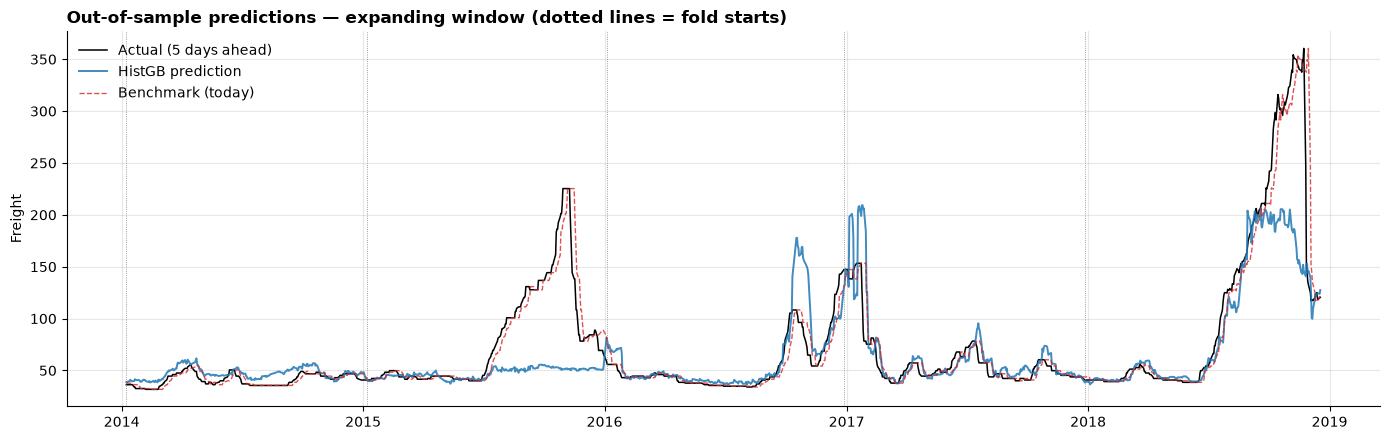

In [153]:
p = preds[(preds["scheme"] == "expanding (default)") & (preds["model"] == "HistGB")]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["Date"], p["actual"], color="black", lw=1.1, label="Actual (5 days ahead)")
ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.4, alpha=0.85, label="HistGB prediction")
ax.plot(p["Date"], p["benchmark"], color="tab:red", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")
for f, g in p.groupby("fold"):
    ax.axvline(g["Date"].min(), color="grey", lw=0.6, ls=":")   # start of each test fold
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Out-of-sample predictions — expanding window (dotted lines = fold starts)", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

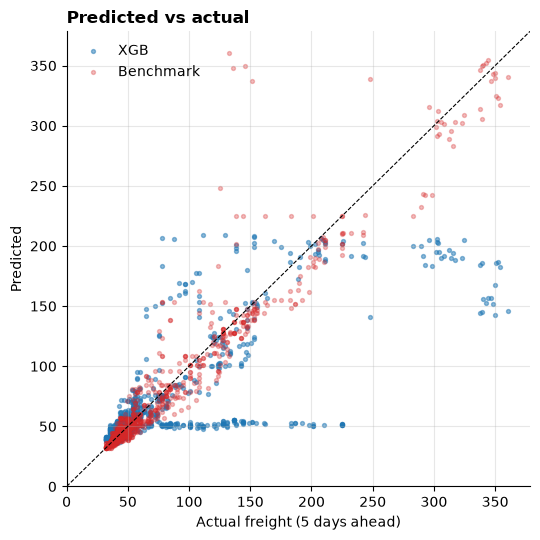

In [154]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(p["actual"], p["pred"], s=8, alpha=0.5, color="tab:blue", label="XGB")
ax.scatter(p["actual"], p["benchmark"], s=8, alpha=0.3, color="tab:red", label="Benchmark")
lim = [0, max(p["actual"].max(), p["pred"].max()) * 1.05]
ax.plot(lim, lim, color="black", lw=0.8, ls="--")   # perfect prediction line
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual freight (5 days ahead)"); ax.set_ylabel("Predicted")
ax.set_title("Predicted vs actual", loc="left", fontweight="bold")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Predicting change not the price

In [155]:
models = {
    #"Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5, random_state=42, n_jobs=-1),
    # "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
preds = []   # store every prediction for plotting
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        **metrics(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train - X_train["Freight"])            # CHANGED: learn the 5-day change, not the price
            y_pred = X_test["Freight"].values + model.predict(X_test)    # CHANGED: add today's price back
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            **metrics(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name, "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)

In [156]:
metric_cols = ["MAE", "RMSE", "MAPE_%", "MaxErr", "R2", "MAE_spike"]
res.pivot_table(index=["scheme", "fold"], columns="model", values=metric_cols).round(2)

MAE                      MAE_spike  \
model                    Benchmark (today) RandomForest Benchmark (today)   
scheme              fold                                                    
expanding (default) 0                 2.27         2.31               NaN   
                    1                 8.02         9.30             20.56   
                    2                 5.43         6.35             20.63   
                    3                 6.50         6.93              8.21   
                    4                12.65        13.60             27.22   
rolling (500)       0                 2.27         2.31               NaN   
                    1                 8.02         9.30             20.56   
                    2                 5.43         6.03             20.63   
                    3                 6.50         7.73              8.21   
                    4                12.65        16.10             27.22   

                                                 MAPE_%               \
model                    RandomForest Benchmark (today) RandomForest   
scheme              fold                                               
expanding (default) 0             NaN              5.36         5.57   
                    1           23.24              8.06         9.41   
                    2           24.73              7.73        10.17   
                    3            7.20             10.51        11.68   
                    4           30.81              9.47         9.66   
rolling (500)       0             NaN              5.36         5.57   
                    1           23.24              8.06         9.41   
                    2           23.89              7.73         9.36   
                    3            7.13             10.51        13.32   
                    4           35.11              9.47        11.75   

                                    MaxErr                             R2  \
model                    Benchmark (today) RandomForest Benchmark (today)   
scheme              fold                                                    
expanding (default) 0                11.25        11.84              0.69   
                    1                87.00        82.31              0.90   
                    2                33.00        33.09              0.85   
                    3                75.00        74.63              0.81   
                    4               227.70       207.50              0.90   
rolling (500)       0                11.25        11.84              0.69   
                    1                87.00        82.31              0.90   
                    2                33.00        32.80              0.85   
                    3                75.00        75.30              0.81   
                    4               227.70       213.57              0.90   

                                                   RMSE               
model                    RandomForest Benchmark (today) RandomForest  
scheme              fold                                              
expanding (default) 0            0.68              3.28         3.34  
                    1            0.90             15.83        16.01  
                    2            0.85              9.55         9.48  
                    3            0.81             11.96        12.05  
                    4            0.91             31.67        30.68  
rolling (500)       0            0.68              3.28         3.34  
                    1            0.90             15.83        16.01  
                    2            0.86              9.55         9.24  
                    3            0.78             11.96        12.79  
                    4            0.89             31.67        32.49

In [157]:
res.groupby(["scheme", "model"])[metric_cols].mean().round(3)

MAE    RMSE  MAPE_%  MaxErr     R2  \
scheme              model                                                     
expanding (default) Benchmark (today)  6.974  14.460   8.227  86.790  0.829   
                    RandomForest       7.699  14.312   9.299  81.874  0.827   
rolling (500)       Benchmark (today)  6.974  14.460   8.227  86.790  0.829   
                    RandomForest       8.293  14.772   9.883  83.164  0.822   

                                       MAE_spike  
scheme              model                         
expanding (default) Benchmark (today)     19.153  
                    RandomForest          21.497  
rolling (500)       Benchmark (today)     19.153  
                    RandomForest          22.343

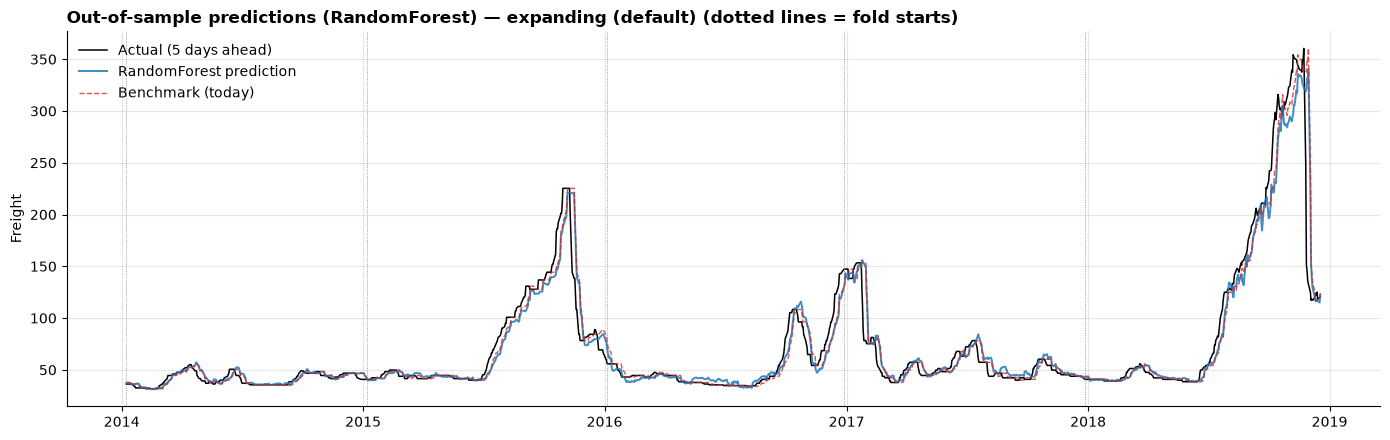

In [158]:

plot_predictions(preds, "RandomForest")

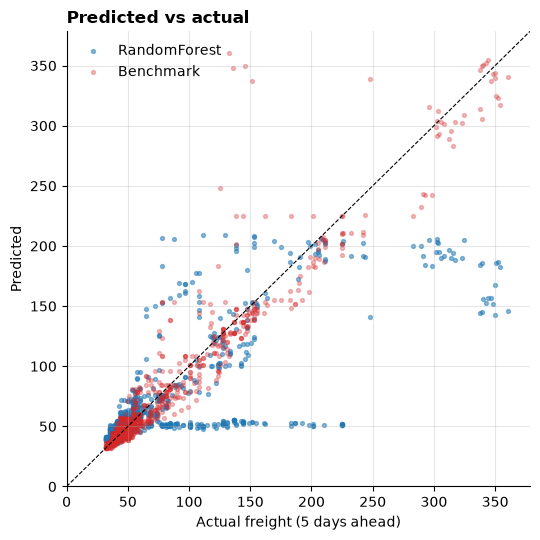

In [159]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(p["actual"], p["pred"], s=8, alpha=0.5, color="tab:blue", label="RandomForest")
ax.scatter(p["actual"], p["benchmark"], s=8, alpha=0.3, color="tab:red", label="Benchmark")
lim = [0, max(p["actual"].max(), p["pred"].max()) * 1.05]
ax.plot(lim, lim, color="black", lw=0.8, ls="--")   # perfect prediction line
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual freight (5 days ahead)"); ax.set_ylabel("Predicted")
ax.set_title("Predicted vs actual", loc="left", fontweight="bold")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [169]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

H = 5
freight = df_model["Freight"].to_numpy()

# exogenous variables known 5 days ahead (n + 5 rows, so the last origins can be forecast)
future_dates = pd.bdate_range(dates.iloc[-1], periods=H + 1)[1:]
all_dates = pd.DatetimeIndex(pd.concat([dates, pd.Series(future_dates)], ignore_index=True))
doy = all_dates.dayofyear
kaub_full = np.r_[df_model["Kaub_level"].to_numpy(), np.full(H, np.nan)]
exog_full = pd.DataFrame({
    "sin1": np.sin(2 * np.pi * doy / 365.25), "cos1": np.cos(2 * np.pi * doy / 365.25),   # yearly cycle
    "sin2": np.sin(4 * np.pi * doy / 365.25), "cos2": np.cos(4 * np.pi * doy / 365.25),   # half-year cycle
    "kaub_lag5": pd.Series(kaub_full).shift(H),   # Kaub 5 days ago: known for every forecast step
}).to_numpy()


def run_sarimax(order, seasonal_order=(0, 0, 0, 0), exog_cols=None, log=False, label="SARIMA"):
    """Fit on each training fold, then walk through the test fold one day at a time:
    add that day's price to the model (no refit) and forecast 5 steps ahead."""
    endog = np.log(freight) if log else freight
    ex = None if exog_cols is None else exog_full[:, exog_cols]
    results, preds = [], []
    for scheme, tscv in splitters.items():
        for fold, (train_idx, test_idx) in enumerate(tscv.split(df_model)):
            tr = slice(max(train_idx[0], H), train_idx[-1] + 1)        # skip first 5 rows (kaub_lag5 = NaN)
            fit = SARIMAX(endog[tr], exog=None if ex is None else ex[tr],
                          order=order, seasonal_order=seasonal_order).fit(disp=False)

            y_pred = []
            for t in range(train_idx[-1] + 1, test_idx[-1] + 1):        # gap rows + test rows
                fit = fit.extend(endog[t:t + 1], exog=None if ex is None else ex[t:t + 1])
                if t >= test_idx[0]:
                    fc = fit.forecast(H, exog=None if ex is None else ex[t + 1:t + 1 + H])
                    y_pred.append(fc[-1])                               # 5th step = price in 5 days
            y_pred = np.exp(y_pred) if log else np.array(y_pred)

            y_test = y.iloc[test_idx].to_numpy()
            bench = df_model["pred_hoje"].iloc[test_idx].to_numpy()
            results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)", **metrics(y_test, bench)})
            results.append({"scheme": scheme, "fold": fold, "model": label, **metrics(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": label,
                                       "Date": dates.iloc[test_idx].values, "actual": y_test,
                                       "pred": y_pred, "benchmark": bench}))
    return pd.DataFrame(results), pd.concat(preds, ignore_index=True)

In [176]:
# Run time ~3min
warnings.filterwarnings("ignore")   # statsmodels warns about the irregular (business-day) index

configs = [
    dict(order=(1, 1, 1), label="ARIMA(1,1,1)"),
    dict(order=(1, 1, 1), seasonal_order=(1, 0, 1, 5), label="SARIMA(1,1,1)(1,0,1,5)"),   # weekly seasonality
    dict(order=(1, 1, 1), exog_cols=[0, 1, 2, 3], label="ARIMA + Fourier"),               # yearly seasonality
    dict(order=(1, 1, 1), log=True, label="log-ARIMA(1,1,1)"),
    dict(order=(1, 1, 1), exog_cols=[4], log=True, label="log-ARIMA + Kaub"),
]

res_list, preds_list = [], []
for cfg in configs:
    r, p = run_sarimax(**cfg)
    res_list.append(r); preds_list.append(p)

res_sarima = pd.concat(res_list).drop_duplicates(["scheme", "fold", "model"])
preds_sarima = pd.concat(preds_list, ignore_index=True)
print(res_sarima.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

                                             MAE   RMSE  MaxErr
scheme              model                                      
expanding (default) ARIMA + Fourier         6.60  13.88   89.00
                    ARIMA(1,1,1)            6.43  13.78   88.87
                    Benchmark (today)       6.97  14.46   86.79
                    SARIMA(1,1,1)(1,0,1,5)  6.44  13.78   89.62
                    log-ARIMA + Kaub        6.28  13.40   88.80
                    log-ARIMA(1,1,1)        6.24  13.38   88.72
rolling (500)       ARIMA + Fourier         6.63  13.89   88.66
                    ARIMA(1,1,1)            6.46  13.80   88.77
                    Benchmark (today)       6.97  14.46   86.79
                    SARIMA(1,1,1)(1,0,1,5)  6.57  13.94   90.14
                    log-ARIMA + Kaub        6.42  13.51   88.59
                    log-ARIMA(1,1,1)        6.31  13.43   88.42


-   **Log transformation:** the model is fitted on log(price) and the forecasts are converted back with exp(). In logs, equal percentage changes become equal absolute changes (30→40 and 150→200 are both +0.29). Freight price movements are roughly proportional to the price level (small moves at low prices, large moves during low-water spikes), so the log stabilises the variance, as ARIMA assumes, and lets the model learn momentum in percentage terms. It also guarantees positive forecasts. This reduced the MAE of ARIMA(1,1,1) from 6.43 to 6.24.

In [177]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_model(preds, model_name, scheme="expanding (default)", last_n=None, start=None, end=None):
    p = preds[(preds["scheme"] == scheme) & (preds["model"] == model_name)].sort_values("Date")

    # zoom window
    if start is not None: p = p[p["Date"] >= pd.Timestamp(start)]
    if end   is not None: p = p[p["Date"] <= pd.Timestamp(end)]
    if last_n is not None: p = p.tail(last_n)

    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(p["Date"], p["actual"], color="black", lw=1.4, label="Actual (5 days ahead)")
    ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.1, alpha=0.85, label=f"{model_name} prediction")
    ax.plot(p["Date"], p["benchmark"], color="tab:grey", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")

    # fold starts, only if they fall inside the window
    lo, hi = p["Date"].min(), p["Date"].max()
    for f, g in preds[(preds["scheme"] == scheme) & (preds["model"] == model_name)].groupby("fold"):
        d0 = g["Date"].min()
        if lo <= d0 <= hi:
            ax.axvline(d0, color="grey", lw=0.6, ls=":")

    ax.set_xlim(lo, hi)
    span = (hi - lo).days
    if span > 700:
        ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    else:
        ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
    ax.set_title(f"Out-of-sample predictions, {model_name}, {scheme}", loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [179]:
preds_sarima[["scheme", "model"]].drop_duplicates()

,scheme,model
0,expanding (default),"ARIMA(1,1,1)"
1205,rolling (500),"ARIMA(1,1,1)"
2410,expanding (default),"SARIMA(1,1,1)(1,0,1,5)"
3615,rolling (500),"SARIMA(1,1,1)(1,0,1,5)"
4820,expanding (default),ARIMA + Fourier
6025,rolling (500),ARIMA + Fourier
7230,expanding (default),"log-ARIMA(1,1,1)"
8435,rolling (500),"log-ARIMA(1,1,1)"
9640,expanding (default),log-ARIMA + Kaub
10845,rolling (500),log-ARIMA + Kaub


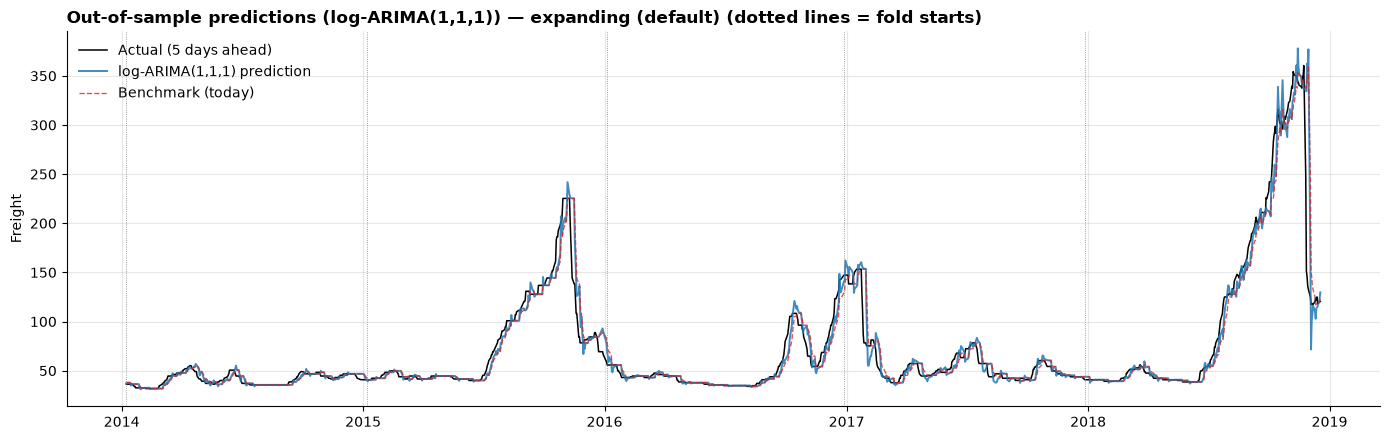

In [190]:
plot_predictions(preds_sarima, "log-ARIMA(1,1,1)")

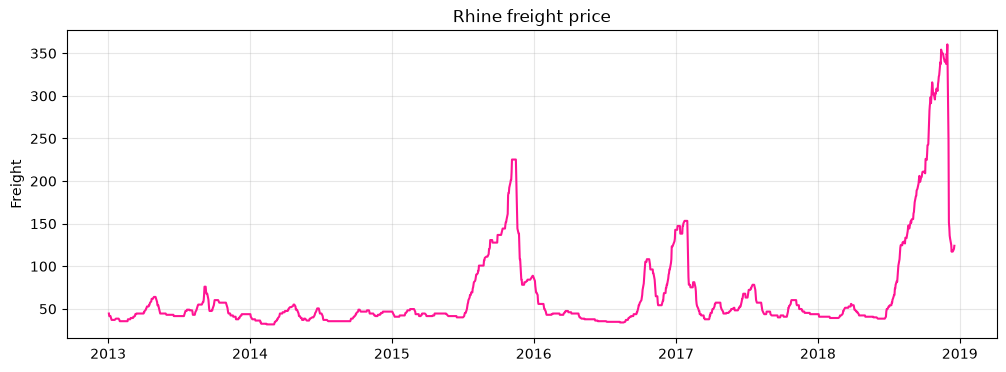

In [163]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore")   # statsmodels warns about the business-day index

freight = df_model.set_index("Date")["Freight"]
log_freight = np.log(freight)       # freight moves in % terms -> model the log

plt.figure(figsize=(12, 4))
plt.plot(freight, linewidth=1.5, c="deeppink")
plt.title("Rhine freight price"); plt.ylabel("Freight"); plt.grid(alpha=0.3)
plt.show()

In [164]:
# Check stationarity of the series
def check_stationarity(timeseries, name):
    result = adfuller(timeseries.dropna(), autolag="AIC")
    print(f"{name:12s} ADF = {result[0]:6.2f} | p-value = {result[1]:.4f} | "
          f"{'stationary' if result[1] < 0.05 else 'non-stationary'}")

check_stationarity(freight, "Freight")              # ADF -3.13, p = 0.025
check_stationarity(log_freight, "log Freight")      # ADF -2.95, p = 0.040
check_stationarity(log_freight.diff(), "diff(log)") # ADF -11.59, p < 0.0001

Freight      ADF =  -3.00 | p-value = 0.0354 | stationary
log Freight  ADF =  -2.91 | p-value = 0.0442 | stationary
diff(log)    ADF = -11.56 | p-value = 0.0000 | stationary


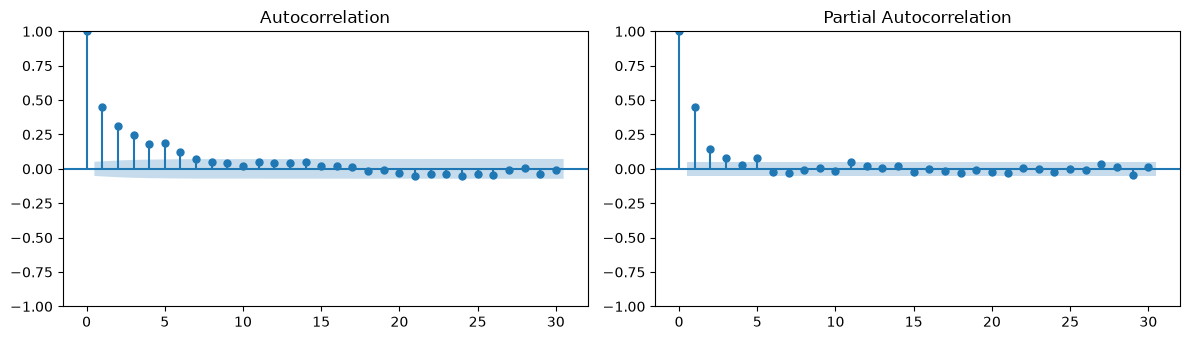

In [165]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(log_freight.diff().dropna(), lags=30, ax=axes[0])
plot_pacf(log_freight.diff().dropna(), lags=30, ax=axes[1])
plt.tight_layout(); plt.show()

In [166]:
test_start = "2018-01-01"
train = log_freight[log_freight.index < test_start]
test = freight[freight.index >= test_start]
print(len(train), len(test))    # 1211 training days, 243 test days

p, d, q = 1, 1, 1
P, D, Q, s = 1, 0, 1, 5         # weekly seasonality (5 business days)

model = SARIMAX(train.values, order=(p, d, q), seasonal_order=(P, D, Q, s))
results = model.fit(disp=False)
print(results.summary().tables[1])

1211 238
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7676      0.025     30.849      0.000       0.719       0.816
ma.L1         -0.4121      0.034    -12.068      0.000      -0.479      -0.345
ar.S.L5       -0.3402      0.362     -0.941      0.347      -1.049       0.368
ma.S.L5        0.3969      0.349      1.138      0.255      -0.286       1.080
sigma2         0.0008   1.64e-05     50.727      0.000       0.001       0.001


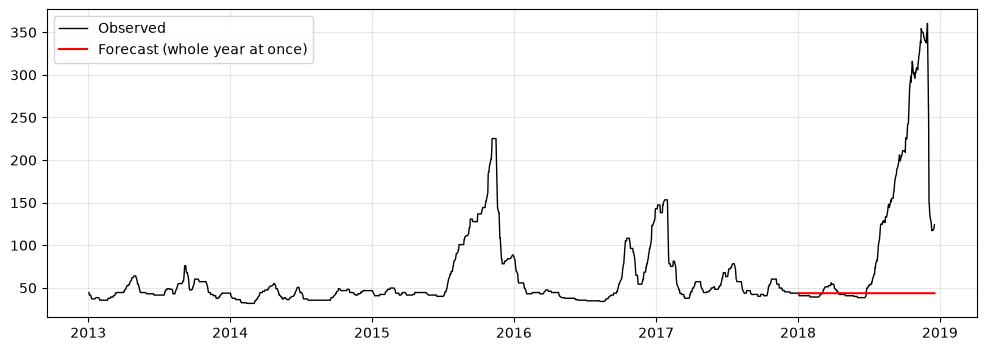

MAE: 76.80321300361817


In [167]:
forecast = np.exp(results.forecast(steps=len(test)))   # back from log to price

plt.figure(figsize=(12, 4))
plt.plot(freight, label="Observed", c="black", lw=1)
plt.plot(test.index, forecast, label="Forecast (whole year at once)", c="red")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("MAE:", mean_absolute_error(test, forecast))     # ≈ 76.8

SARIMA     MAE = 11.47 | RMSE = 31.58
Benchmark  MAE = 12.98 | RMSE = 32.21


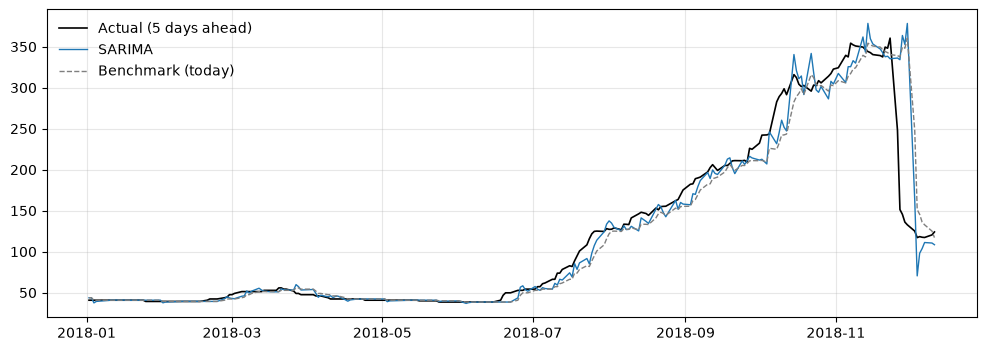

In [168]:
H = 5
series = log_freight.values
n_train = len(train)
fit = results
pred, actual, bench, pred_dates = [], [], [], []

for t in range(n_train, len(series) - H):
    fit = fit.extend(series[t:t + 1])                   # add today's price (no refit)
    pred.append(np.exp(fit.forecast(H)[-1]))            # price in 5 business days
    actual.append(np.exp(series[t + H]))
    bench.append(np.exp(series[t]))                     # benchmark: price today
    pred_dates.append(log_freight.index[t])

print(f"SARIMA     MAE = {mean_absolute_error(actual, pred):.2f} | RMSE = {np.sqrt(mean_squared_error(actual, pred)):.2f}")
print(f"Benchmark  MAE = {mean_absolute_error(actual, bench):.2f} | RMSE = {np.sqrt(mean_squared_error(actual, bench)):.2f}")
# SARIMA MAE 11.33 | RMSE 31.25 ; Benchmark MAE 12.77 | RMSE 31.87

plt.figure(figsize=(12, 4))
plt.plot(pred_dates, actual, label="Actual (5 days ahead)", c="black", lw=1.2)
plt.plot(pred_dates, pred, label="SARIMA", c="tab:blue", lw=1)
plt.plot(pred_dates, bench, label="Benchmark (today)", c="tab:grey", ls="--", lw=1)
plt.legend(frameon=False); plt.grid(alpha=0.3); plt.show()

In [172]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")   # statsmodels warns about the irregular (business-day) index

H = 5                                          # forecast horizon (business days)
ORDER = (1, 1, 1)                              # (p, d, q)
SEASONAL_ORDER = (1, 0, 1, 5)                  # (P, D, Q, s): weekly seasonality
log_freight = np.log(df_model["Freight"].to_numpy())   # model the log price (moves in % terms)

results_sarima, preds_sarima = [], []
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(df_model)):
        # 1) fit on the training fold only
        fit = SARIMAX(log_freight[train_idx], order=ORDER, seasonal_order=SEASONAL_ORDER).fit(disp=False)

        # 2) walk through the gap + test rows: add each day's price (no refit), forecast 5 days ahead
        y_pred = []
        for t in range(train_idx[-1] + 1, test_idx[-1] + 1):
            fit = fit.extend(log_freight[t:t + 1])
            if t >= test_idx[0]:
                y_pred.append(np.exp(fit.forecast(H)[-1]))   # 5th step = price in 5 days, back from log
        y_pred = np.array(y_pred)

        # 3) evaluate against the target and the "price today" benchmark
        y_test = y.iloc[test_idx].to_numpy()
        bench = df_model["pred_hoje"].iloc[test_idx].to_numpy()
        results_sarima.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)", **metrics(y_test, bench)})
        results_sarima.append({"scheme": scheme, "fold": fold, "model": "SARIMA", **metrics(y_test, y_pred)})
        preds_sarima.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": "SARIMA",
                                          "Date": dates.iloc[test_idx].values, "actual": y_test,
                                          "pred": y_pred, "benchmark": bench}))

res_sarima = pd.DataFrame(results_sarima)
preds_sarima = pd.concat(preds_sarima, ignore_index=True)
print(res_sarima.pivot(index=["scheme", "fold"], columns="model", values="MAE").round(2))
print(res_sarima.groupby(["scheme", "model"])[["MAE", "RMSE", "MaxErr"]].mean().round(2))

KeyboardInterrupt: 